# Week 4 - Univariate Analysis, part 2

# 1. Lesson - None

# 2. Weekly graph question

Below are a histogram and boxplot representation of the same data. A pharmacy is keeping a record of the prices of the drugs that it sells, and an administrator wants to know how much the more expensive drugs tend to cost, in the context of the other prices.

Please write a short explanation of the pros and cons of these two representations. Which would you choose? How would you modify the formatting, if at all, to make it more visually interesting, clear, or informative?

In [1]:
import numpy as np
import pandas as pd

np.random.seed(0)
num_data = 100
data = np.exp(np.random.uniform(size = num_data) * 4)
df = pd.DataFrame(data.T, columns = ["data"])

The 75th percentile is: data    15.457656
Name: 0.75, dtype: float64


<Axes: ylabel='Frequency'>

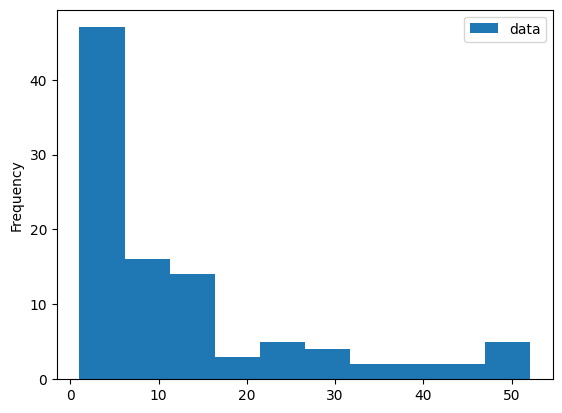

In [2]:
print("The 75th percentile is:", df.quantile(q = 0.75))
df.plot.hist()

<Axes: >

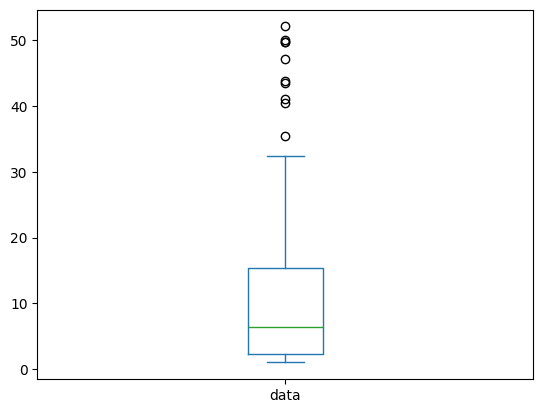

In [3]:
df.plot.box()

I think both graphs are useful, but they show the data in different ways. The histogram gives a better idea of how the drug prices are distributed and where most of the prices are concentrated. The boxplot is simpler and makes it easier to identify the median, quartiles, and more expensive values or outliers. For this example, I would probably choose the boxplot because the administrator is mainly interested in the higher drug prices compared with the rest of the data. I would add a clear title and label the axis with something like “Drug Price ($)” I also think showing the 75th percentile would make the graph more informative and easier to understand.

# 3. Homework - working on your chosen project datasets this semester

The dataset contains yearly data from 1995 to 2025. Most of the columns are economic indicators. I will use histograms and boxplots to look at their distributions. I will not include the year column in these calculations.

In [29]:
import matplotlib.pyplot as plt
df = pd.read_csv("ecuador_macro_wide.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (31, 10)


,year,inflation_cpi_annual_pct,gdp_growth_annual_pct,gdp_current_usd,unemployment_pct,fx_rate_lcus_per_usd,population,oil_rents_pct_gdp,household_consumption_growth_pct,cpi_index_2010_100
0,1995,22.9341,2.2525,2.443288e+10,4.408,2564.4942,11590514.0,6.4537,3.9843,6.9194
1,1996,24.4115,1.7317,2.522639e+10,4.422,3189.4742,11810950.0,7.7879,1.2647,8.6086
2,1997,30.6576,4.3279,2.816205e+10,4.424,3998.2667,12031127.0,6.1722,5.9587,11.2478
3,1998,36.0984,3.2665,2.798190e+10,4.389,5446.5729,12251184.0,3.2121,6.8838,15.3080
4,1999,52.2420,-4.7394,1.964527e+10,4.656,11786.8017,12470795.0,7.8633,-12.1964,23.3052


In [28]:
df.info()
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   year                              31 non-null     int64  
 1   inflation_cpi_annual_pct          31 non-null     float64
 2   gdp_growth_annual_pct             31 non-null     float64
 3   gdp_current_usd                   31 non-null     float64
 4   unemployment_pct                  31 non-null     float64
 5   fx_rate_lcus_per_usd              31 non-null     float64
 6   population                        31 non-null     float64
 7   oil_rents_pct_gdp                 27 non-null     float64
 8   household_consumption_growth_pct  31 non-null     float64
 9   cpi_index_2010_100                31 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 2.6 KB
Index(['year', 'inflation_cpi_annual_pct', 'gdp_growth_annual_pct',
       'gdp_current_usd

In [27]:
print("Missing values in each column:")
display(df.isna().sum())
df[df.isna().any(axis=1)]

Missing values in each column:


,0
year,0
inflation_cpi_annual_pct,0
gdp_growth_annual_pct,0
gdp_current_usd,0
unemployment_pct,0
fx_rate_lcus_per_usd,0
population,0
oil_rents_pct_gdp,4
household_consumption_growth_pct,0
cpi_index_2010_100,0


,year,inflation_cpi_annual_pct,gdp_growth_annual_pct,gdp_current_usd,unemployment_pct,fx_rate_lcus_per_usd,population,oil_rents_pct_gdp,household_consumption_growth_pct,cpi_index_2010_100
27,2022,3.4662,5.8684,1.161331e+11,3.713,1.0,17823897.0,NaN,5.9992,128.1810
28,2023,2.2157,1.8328,1.207928e+11,3.510,1.0,17980083.0,NaN,3.6281,131.0211
29,2024,1.5473,-1.9441,1.238024e+11,3.453,1.0,18135478.0,NaN,-1.6526,133.0484
30,2025,0.7105,3.7259,1.303206e+11,3.308,1.0,18289896.0,NaN,2.7379,133.9937


Most of the data is complete. Oil rents is the only column with missing values, with four missing observations from 2022 to 2025. I can still use the data, but I need to keep these missing values in mind.

In [26]:
numeric_cols = df.columns.drop("year")

df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
inflation_cpi_annual_pct,31.0,1.219052e+01,2.049668e+01,-3.389000e-01,1.948300e+00,3.554400e+00,1.044185e+01,9.609640e+01
gdp_growth_annual_pct,31.0,2.970419e+00,3.824968e+00,-9.245100e+00,1.091400e+00,3.725900e+00,5.590900e+00,9.421900e+00
gdp_current_usd,31.0,6.964709e+10,3.772462e+10,1.753945e+10,2.956363e+10,6.815133e+10,1.035926e+11,1.303206e+11
unemployment_pct,31.0,4.102419e+00,7.282920e-01,3.083000e+00,3.520000e+00,3.917000e+00,4.550500e+00,6.116000e+00
fx_rate_lcus_per_usd,31.0,8.713422e+02,2.434427e+03,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.178680e+04
population,31.0,1.505587e+07,2.121631e+06,1.159051e+07,1.325539e+07,1.507670e+07,1.690453e+07,1.828990e+07
oil_rents_pct_gdp,27.0,9.700596e+00,4.905173e+00,2.562800e+00,6.287750e+00,8.391500e+00,1.313090e+01,1.865460e+01
household_consumption_growth_pct,31.0,2.420935e+00,5.377310e+00,-1.219640e+01,1.457950e+00,3.628100e+00,5.546150e+00,1.112930e+01
cpi_index_2010_100,31.0,8.937539e+01,4.086371e+01,6.919400e+00,7.357985e+01,1.000000e+02,1.237677e+02,1.339937e+02


In [25]:
print("Median:")
display(df[numeric_cols].median())

Median:


,0
inflation_cpi_annual_pct,3.554400e+00
gdp_growth_annual_pct,3.725900e+00
gdp_current_usd,6.815133e+10
unemployment_pct,3.917000e+00
fx_rate_lcus_per_usd,1.000000e+00
population,1.507670e+07
oil_rents_pct_gdp,8.391500e+00
household_consumption_growth_pct,3.628100e+00
cpi_index_2010_100,1.000000e+02


Looking at the mean and median, inflation stands out because the mean is much higher than the median. This happens because there are a few years with very high inflation. Most of the variables do not have a useful mode because the values do not repeat very often.

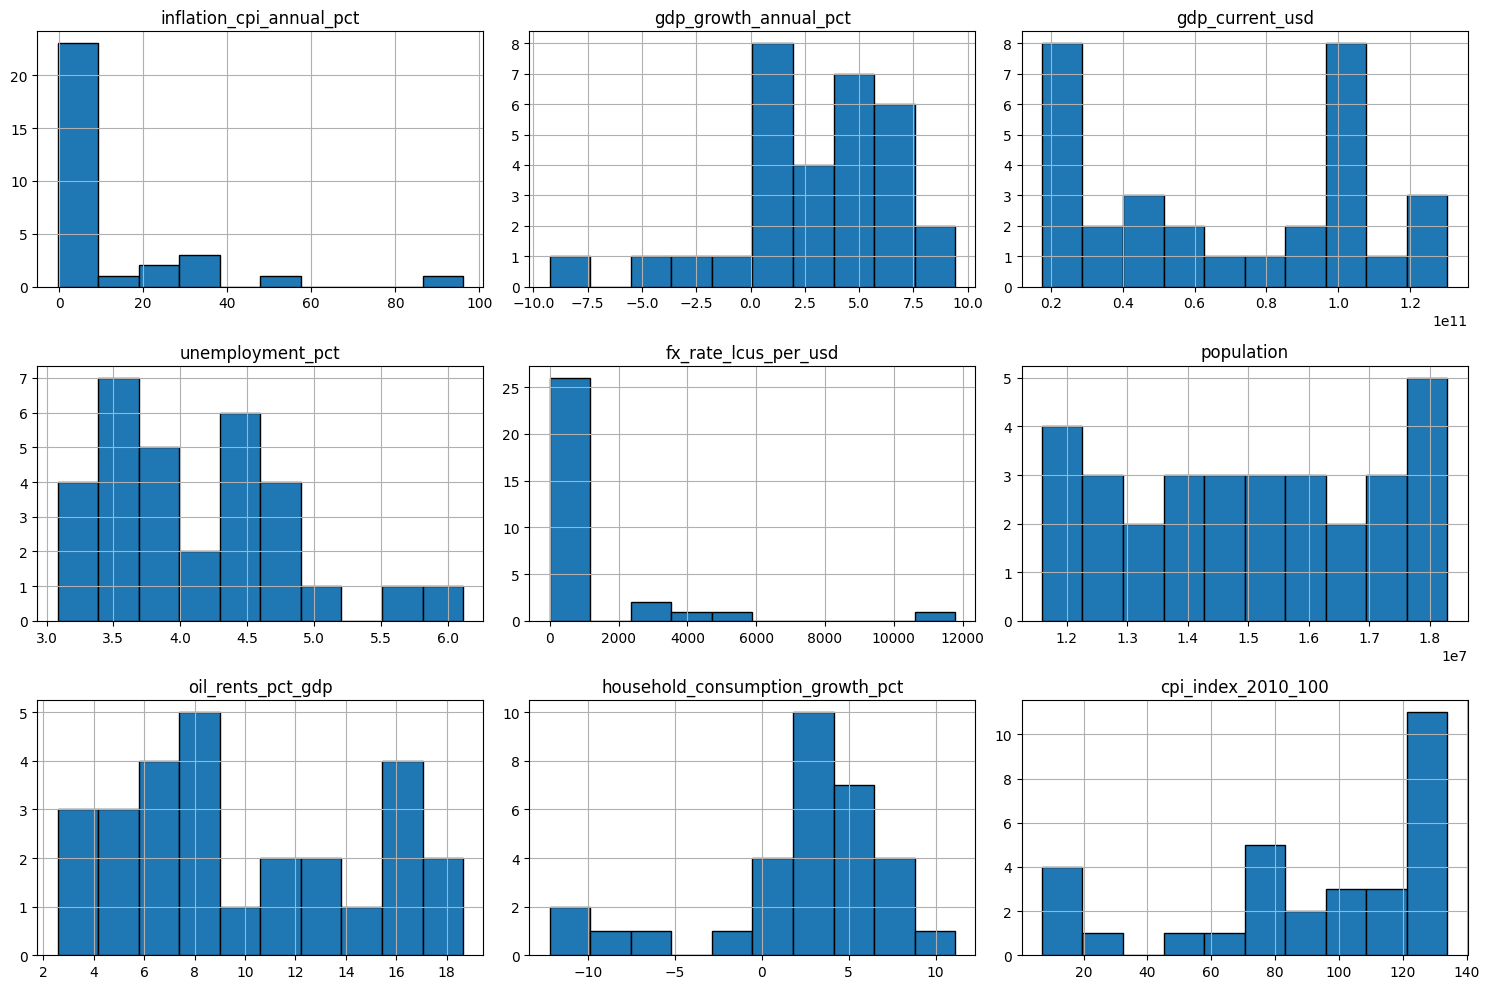

In [24]:
df[numeric_cols].hist(
    bins=10,
    figsize=(15, 10),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

Looking at the histograms, the variables have different distributions. Inflation is right-skewed because most years have lower inflation, but there are a few years with very high values. GDP growth and household consumption also have some unusually low values.
The exchange rate looks very different from the other variables. Most of the values are around 1, while some of the earlier years have much higher values. This is something I would need to look at more carefully later in the project.

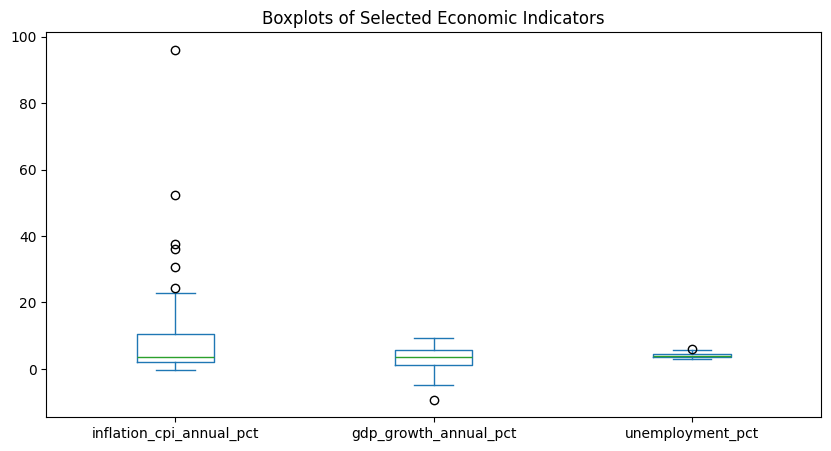

In [23]:
df[
    [
        "inflation_cpi_annual_pct",
        "gdp_growth_annual_pct",
        "unemployment_pct"
    ]
].plot.box(figsize=(10, 5))

plt.title("Boxplots of Selected Economic Indicators")
plt.show()

The boxplots show some possible outliers. Inflation has some very high values, and GDP growth has a very low value around 2020. I would not remove these values because they could represent real economic events and not errors in the data.

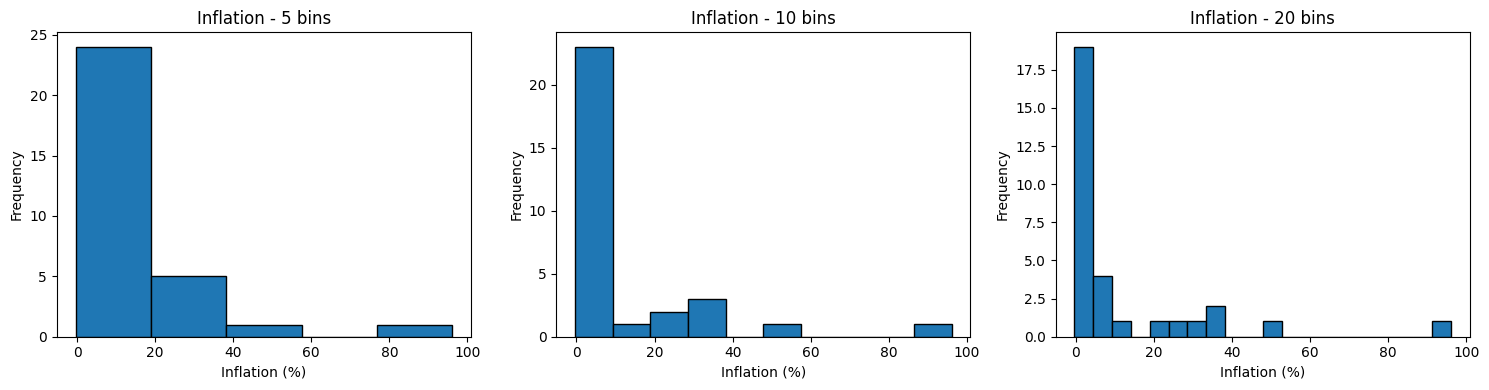

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

bin_options = [5, 10, 20]

for ax, bins in zip(axes, bin_options):

    ax.hist(
        df["inflation_cpi_annual_pct"].dropna(),
        bins=bins,
        edgecolor="black"
    )

    ax.set_title(f"Inflation - {bins} bins")
    ax.set_xlabel("Inflation (%)")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

The number of bins changes how the histogram looks. With 5 bins, the graph is simpler but shows less detail. With 20 bins, we can see more detail, but the graph looks more irregular. I think 10 bins works well for this dataset.

### Conclusions

Overall, I think this dataset can work for my project. Most of the data is complete, except for four missing values in the oil rents column.
The histograms show that the variables have different distributions. Inflation is very right-skewed because there are a few years with very high inflation. GDP growth also has some unusually low values, especially around 2020. The boxplots helped me see some possible outliers, but I would not remove them automatically because they may represent real economic events.
I also noticed that changing the number of bins can make the histogram look different. Since this dataset only has 31 yearly observations, too many bins can make the graph harder to understand.
One limitation is that histograms do not show when the changes happened.

# 4. Storytelling With Data graph

Reproduce any graph of your choice in p. 52-68 of the Storytelling With Data book as best you can.  (The second half of chapter two).  You do not have to get the exact data values right, just the overall look and feel.

I chose the waterfall chart from Figure 2.17. It shows how employee headcount changes during the year because of hires, transfers, and exits.

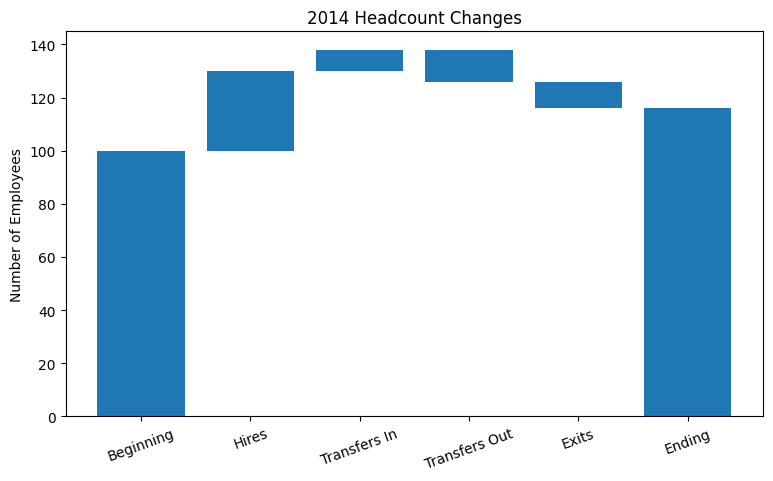

In [21]:
categories = [
    "Beginning",
    "Hires",
    "Transfers In",
    "Transfers Out",
    "Exits",
    "Ending"
]

values = [100, 30, 8, -12, -10, 116]

bottoms = [0, 100, 130, 126, 116, 0]
heights = [100, 30, 8, 12, 10, 116]

plt.figure(figsize=(9, 5))

plt.bar(categories, heights, bottom=bottoms)

plt.title("2014 Headcount Changes")
plt.ylabel("Number of Employees")

plt.xticks(rotation=20)

plt.show()